# Superstore Sales & Demand Forecasting

**Audience:** store owner, startup founder, or operations manager  
**Question:** How much will we sell over the next 8 weeks, and what should we do about it?

This notebook turns four years of Superstore orders into a weekly demand forecast. Accuracy matters, but the goal is a number you can plan inventory, cash, and staffing around.



## 1. Setup

We read the Superstore extract from `data/raw/`, keep a time-based split (never a random shuffle), and write charts and a stakeholder brief into `reports/`.



In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path("..").resolve()
if not (ROOT / "data" / "raw").exists():
    ROOT = Path(".").resolve()

RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
REPORTS_DIR = ROOT / "reports"
FIG_DIR = REPORTS_DIR / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

HOLDOUT_WEEKS = 12
HORIZON_WEEKS = 8
LAGS = (1, 4, 52)
ROLLS = (4, 12)
FEATURE_COLS = [
    "t", "year", "weekofyear", "month", "quarter",
    "lag_1", "lag_4", "lag_52", "roll_4", "roll_12",
]

def find_raw_file() -> Path:
    candidates = list(RAW_DIR.glob("*.csv")) + list(RAW_DIR.glob("*.xlsx")) + list(RAW_DIR.glob("*.xls"))
    preferred = [
        RAW_DIR / "Sample - Superstore.csv",
        RAW_DIR / "superstore_final_dataset.csv",
        RAW_DIR / "Superstore.csv",
    ]
    for path in preferred + candidates:
        if path.exists() and path.name != ".gitkeep":
            return path
    raise FileNotFoundError(
        "Put the Superstore file in data/raw/ as 'Sample - Superstore.csv'.\n"
        "Download: https://www.kaggle.com/datasets/vivek468/superstore-dataset-final"
    )

def mape(y_true, y_pred) -> float:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = np.clip(np.abs(y_true), 1e-8, None)
    return float(np.mean(np.abs(y_true - y_pred) / denom) * 100)

def metrics_row(name, y_true, y_pred) -> dict:
    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MAPE_%": mape(y_true, y_pred),
    }

print("Project root:", ROOT)


Project root: /Users/sam/Desktop/Future_ML_01


## 2. Load and clean historical orders

Keep the columns a planner cares about: when the order happened, how much was sold, and the mix by category, region, and customer segment. Superstore often has a handful of missing postal codes (Burlington, VT in the Tableau extract). This copy may already fill them; we still document and handle them.



In [2]:
raw_path = find_raw_file()
print("Reading", raw_path.name)

if raw_path.suffix.lower() in {".xls", ".xlsx"}:
    orders = pd.read_excel(raw_path)
else:
    orders = pd.read_csv(raw_path, encoding="latin-1")

orders.columns = [c.strip() for c in orders.columns]
print("Raw shape:", orders.shape)
print("Columns:", list(orders.columns))

keep = ["Order Date", "Sales", "Quantity", "Category", "Region", "Segment", "Postal Code"]
missing_cols = [c for c in keep if c not in orders.columns]
if missing_cols:
    raise ValueError(f"Dataset is missing expected columns: {missing_cols}")

n_dup = int(orders.duplicated().sum())
orders = orders.drop_duplicates()

orders["Order Date"] = pd.to_datetime(orders["Order Date"], errors="coerce")
bad_dates = int(orders["Order Date"].isna().sum())
orders = orders.dropna(subset=["Order Date", "Sales"])

postal_missing = int(orders["Postal Code"].isna().sum()) if "Postal Code" in orders.columns else 0
# Known Superstore quirk: Burlington, Vermont rows sometimes lack a ZIP.
if postal_missing:
    orders["Postal Code"] = orders["Postal Code"].fillna("05401")

nonpositive = int((orders["Sales"] <= 0).sum())
# Superstore list prices are positive; treat non-positive sales as data errors if they appear.
if nonpositive:
    orders = orders[orders["Sales"] > 0]

orders = orders[keep].copy()
orders["Order Date"] = orders["Order Date"].dt.normalize()

print(f"Dropped {n_dup} duplicate rows, {bad_dates} bad dates, {nonpositive} non-positive sales.")
print(f"Postal codes filled: {postal_missing}")
print("Clean orders:", len(orders))
print("Date range:", orders["Order Date"].min().date(), "→", orders["Order Date"].max().date())
print("Missing values after clean:\n", orders.isna().sum().to_string())
orders.head()


Reading Sample - Superstore.csv
Raw shape: (9994, 21)
Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
Dropped 0 duplicate rows, 0 bad dates, 0 non-positive sales.
Postal codes filled: 0
Clean orders: 9994
Date range: 2014-01-03 → 2017-12-30
Missing values after clean:
 Order Date     0
Sales          0
Quantity       0
Category       0
Region         0
Segment        0
Postal Code    0


,Order Date,Sales,Quantity,Category,Region,Segment,Postal Code
0,2016-11-08,261.9600,2,Furniture,South,Consumer,42420
1,2016-11-08,731.9400,3,Furniture,South,Consumer,42420
2,2016-06-12,14.6200,2,Office Supplies,West,Corporate,90036
3,2015-10-11,957.5775,5,Furniture,South,Consumer,33311
4,2015-10-11,22.3680,2,Office Supplies,South,Consumer,33311


## 3. Weekly demand series

Daily Superstore sales are spiky (many days with few orders). Weekly totals are what a store actually plans against: replenishment cycles, payroll, and cash. Missing weeks are filled with **0** (no orders that week), not interpolated, so we do not invent demand.



In [3]:
weekly = (
    orders.set_index("Order Date")
    .resample("W-SUN")
    .agg(sales=("Sales", "sum"), quantity=("Quantity", "sum"), orders=("Sales", "size"))
)
full_idx = pd.date_range(weekly.index.min(), weekly.index.max(), freq="W-SUN")
n_gaps = int(len(full_idx) - weekly.index.nunique())
weekly = weekly.reindex(full_idx, fill_value=0)
weekly.index.name = "week_end"
weekly = weekly.reset_index()

weekly_path = PROCESSED_DIR / "weekly_sales.csv"
weekly.to_csv(weekly_path, index=False)
print(f"Filled {n_gaps} empty weeks with 0 sales.")
print("Weekly rows:", len(weekly), "| file:", weekly_path)
print(weekly[["week_end", "sales", "quantity"]].describe().round(1))
weekly.tail()


Filled 0 empty weeks with 0 sales.
Weekly rows: 209 | file: /Users/sam/Desktop/Future_ML_01/data/processed/weekly_sales.csv
                  week_end    sales  quantity
count                  209    209.0     209.0
mean   2016-01-03 00:00:00  10991.4     181.2
min    2014-01-05 00:00:00    227.2      13.0
25%    2015-01-04 00:00:00   5277.8     107.0
50%    2016-01-03 00:00:00   8866.2     158.0
75%    2017-01-01 00:00:00  14973.2     235.0
max    2017-12-31 00:00:00  38176.8     564.0
std                    NaN   7588.7     102.5


,week_end,sales,quantity,orders
204,2017-12-03,32354.5700,564,130
205,2017-12-10,24006.9580,480,131
206,2017-12-17,10495.9630,267,77
207,2017-12-24,23662.3640,372,99
208,2017-12-31,8977.8318,233,67


## 4. What the history is telling a manager

Before modeling, we want three facts: is sales growing, which months are busy, and which categories/regions carry the business.



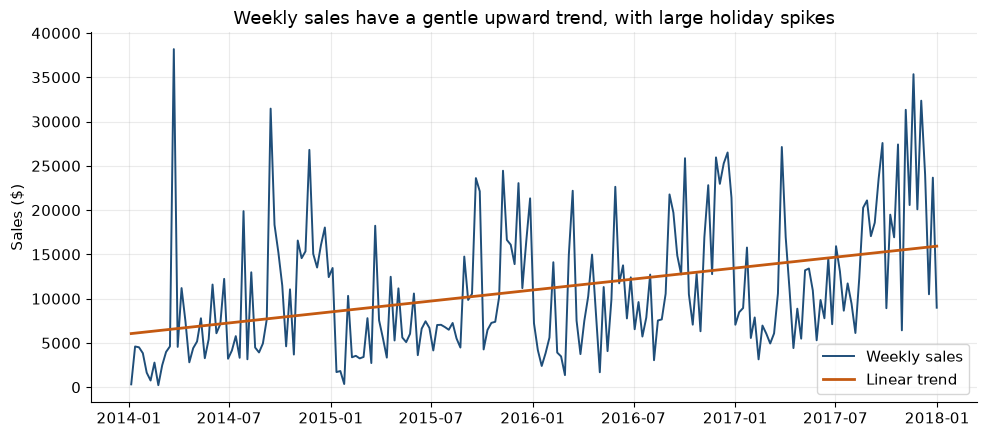

Trend slope: $47 extra sales per week on average.
Mean weekly sales: $10,991 | peak week: $38,177 on 2014-03-23


In [4]:
w = weekly.copy()
w["t"] = np.arange(len(w))
coef = np.polyfit(w["t"], w["sales"], 1)
trend = np.polyval(coef, w["t"])

fig, ax = plt.subplots()
ax.plot(w["week_end"], w["sales"], color="#1f4e79", lw=1.4, label="Weekly sales")
ax.plot(w["week_end"], trend, color="#c45911", lw=2, label="Linear trend")
ax.set_title("Weekly sales have a gentle upward trend, with large holiday spikes")
ax.set_ylabel("Sales ($)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "01_weekly_trend.png", dpi=140)
plt.show()

print(f"Trend slope: ${coef[0]:,.0f} extra sales per week on average.")
print(f"Mean weekly sales: ${w['sales'].mean():,.0f} | peak week: ${w['sales'].max():,.0f} on {w.loc[w['sales'].idxmax(), 'week_end'].date()}")


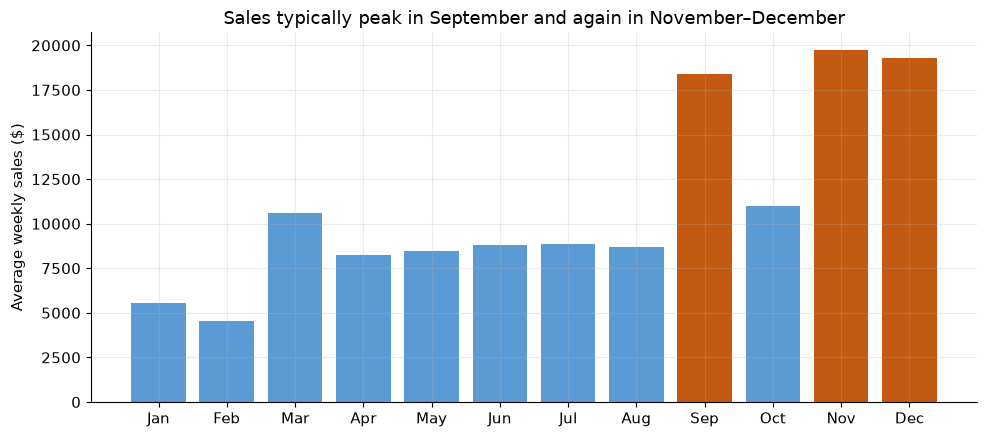

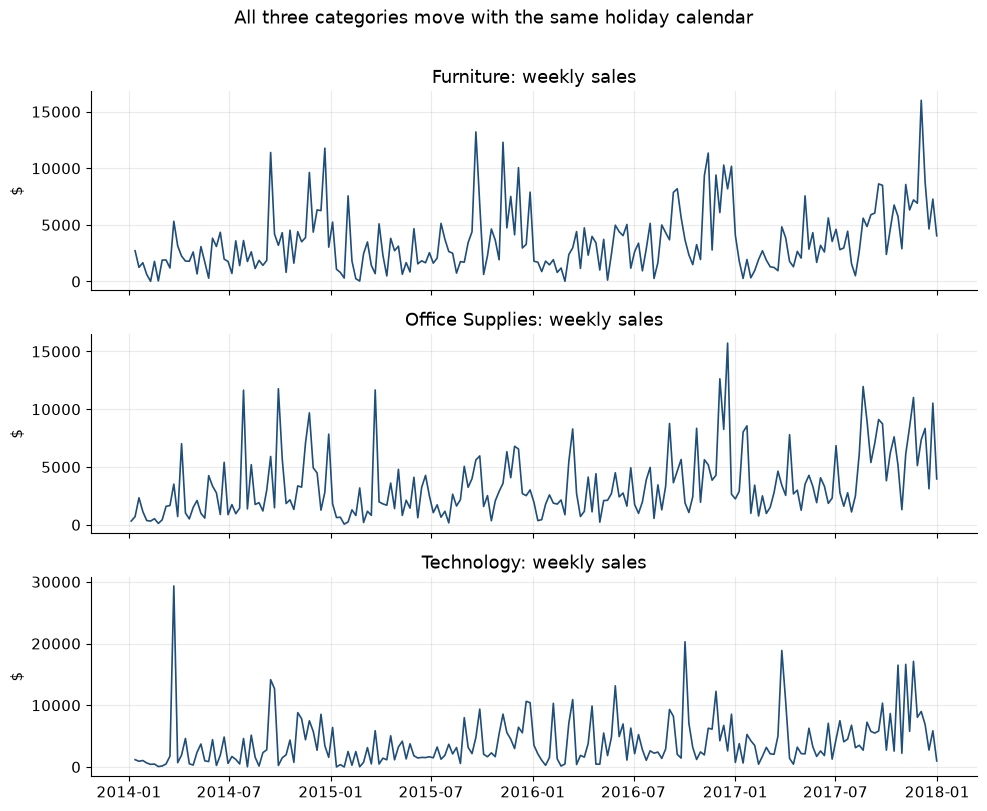

Sales mix by category (%):
Category
Technology         36.4
Furniture          32.3
Office Supplies    31.3

Sales mix by region (%):
Region
West       31.6
East       29.5
Central    21.8
South      17.1


In [5]:
w["month"] = w["week_end"].dt.month
month_avg = w.groupby("month")["sales"].mean()
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots()
colors = ["#c45911" if m in (9, 11, 12) else "#5b9bd5" for m in range(1, 13)]
ax.bar(month_names, month_avg.values, color=colors)
ax.set_title("Sales typically peak in September and again in November–December")
ax.set_ylabel("Average weekly sales ($)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_seasonality_month.png", dpi=140)
plt.show()

cat_week = (
    orders.set_index("Order Date")
    .groupby("Category")
    .resample("W-SUN")["Sales"]
    .sum()
    .unstack(level=0)
    .reindex(full_idx, fill_value=0)
)

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, col in zip(axes, ["Furniture", "Office Supplies", "Technology"]):
    if col in cat_week.columns:
        ax.plot(cat_week.index, cat_week[col], color="#1f4e79", lw=1.2)
        ax.set_title(f"{col}: weekly sales")
        ax.set_ylabel("$")
fig.suptitle("All three categories move with the same holiday calendar", y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_category_small_multiples.png", dpi=140)
plt.show()

mix = orders.groupby("Category")["Sales"].sum().sort_values(ascending=False)
region = orders.groupby("Region")["Sales"].sum().sort_values(ascending=False)
print("Sales mix by category (%):")
print((mix / mix.sum() * 100).round(1).to_string())
print("\nSales mix by region (%):")
print((region / region.sum() * 100).round(1).to_string())


## 5. Time-based features

The model is allowed to know the calendar (month, week of year, trend) and the recent past (last week, last month, same week last year, 4- and 12-week rolling averages). It is **not** allowed to peek at future weeks.



In [6]:
def add_time_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out["week_end"] = pd.to_datetime(out["week_end"])
    out["t"] = np.arange(len(out))
    out["year"] = out["week_end"].dt.year
    out["weekofyear"] = out["week_end"].dt.isocalendar().week.astype(int)
    out["month"] = out["week_end"].dt.month
    out["quarter"] = out["week_end"].dt.quarter
    for lag in LAGS:
        out[f"lag_{lag}"] = out["sales"].shift(lag)
    for win in ROLLS:
        # Rolling stats use only past weeks (shift 1) so the current target never leaks in.
        out[f"roll_{win}"] = out["sales"].shift(1).rolling(win).mean()
    return out

featured = add_time_features(weekly)
model_ready = featured.dropna().reset_index(drop=True)
print("Rows after dropping warmup lags:", len(model_ready), "(need 52 weeks of history for yearly lag)")
model_ready[["week_end", "sales", *FEATURE_COLS]].head()


Rows after dropping warmup lags: 157 (need 52 weeks of history for yearly lag)


,week_end,sales,t,year,weekofyear,month,quarter,lag_1,lag_4,lag_52,roll_4,roll_12
0,2015-01-04,13462.7946,52,2015,1,1,1,12431.3760,13515.0780,324.044,15011.900875,13978.627350
1,2015-01-11,1708.9840,53,2015,2,1,1,13462.7946,16064.3225,4599.572,14998.830025,14715.701733
2,2015-01-18,1827.2760,54,2015,3,1,1,1708.9840,18036.8270,4509.127,11409.995400,13937.217067
3,2015-01-25,358.5220,55,2015,4,1,1,1827.2760,12431.3760,3842.388,7357.607650,13782.009567
4,2015-02-01,10314.5160,56,2015,5,2,1,358.5220,13462.7946,1642.310,4339.394150,12431.287233


## 6. Train on the past, test on the last 12 weeks

The last 12 weeks of history are held out as a dress rehearsal: the model is scored on weeks it has never trained on. That is the same situation a manager faces when planning next quarter.



In [7]:
split = len(model_ready) - HOLDOUT_WEEKS
train = model_ready.iloc[:split].copy()
test = model_ready.iloc[split:].copy()
print("Train:", train["week_end"].min().date(), "→", train["week_end"].max().date(), f"({len(train)} weeks)")
print("Holdout:", test["week_end"].min().date(), "→", test["week_end"].max().date(), f"({len(test)} weeks)")

X_train, y_train = train[FEATURE_COLS], train["sales"]
X_test, y_true = test[FEATURE_COLS], test["sales"]

# Baselines a manager already understands.
naive_ma = np.full(len(test), train["sales"].iloc[-4:].mean())
seasonal = test["lag_52"].to_numpy()  # same week last year

ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=2.0)),
])
ridge.fit(X_train, y_train)
ridge_hat = ridge.predict(X_test)

rf = RandomForestRegressor(
    n_estimators=400,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
)
rf.fit(X_train, y_train)
rf_hat = rf.predict(X_test)

scoreboard = pd.DataFrame([
    metrics_row("Seasonal naive (same week last year)", y_true, seasonal),
    metrics_row("4-week moving average", y_true, naive_ma),
    metrics_row("Ridge (time features + lags)", y_true, ridge_hat),
    metrics_row("Random Forest", y_true, rf_hat),
]).set_index("model")
scoreboard = scoreboard.round(1)
scoreboard


Train: 2015-01-04 → 2017-10-08 (145 weeks)
Holdout: 2017-10-15 → 2017-12-31 (12 weeks)


,MAE,RMSE,MAPE_%
model,,,
Seasonal naive (same week last year),8375.4,10884.2,40.1
4-week moving average,7700.3,9178.4,51.8
Ridge (time features + lags),7932.0,9808.8,53.2
Random Forest,7060.7,8441.2,44.6


Best holdout MAE: Random Forest


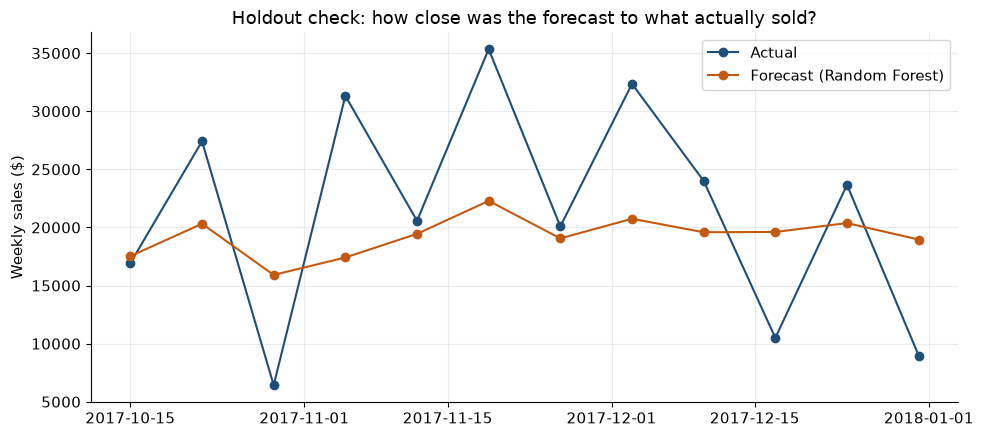

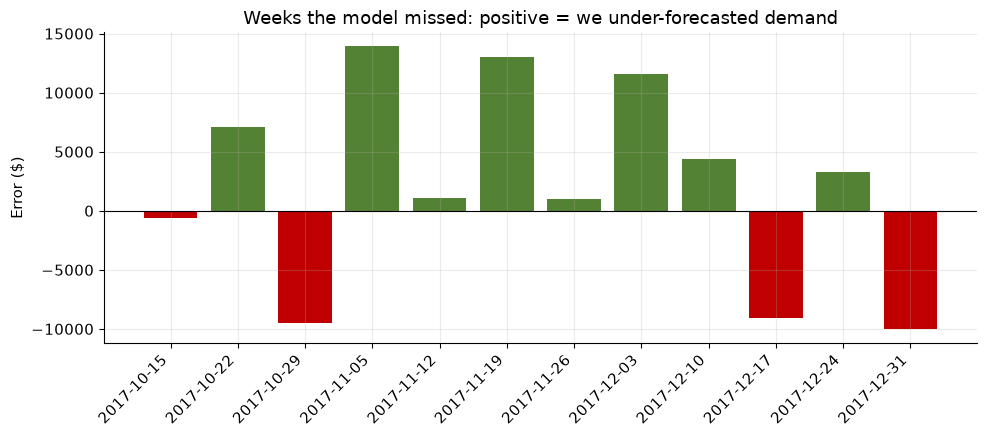

  week_end   sales  predicted   error
2017-10-15 16929.0    17530.0  -601.0
2017-10-22 27412.0    20315.0  7096.0
2017-10-29  6423.0    15916.0 -9492.0
2017-11-05 31326.0    17413.0 13912.0
2017-11-12 20572.0    19447.0  1125.0
2017-11-19 35344.0    22287.0 13058.0
2017-11-26 20087.0    19058.0  1029.0
2017-12-03 32355.0    20746.0 11608.0
2017-12-10 24007.0    19587.0  4420.0
2017-12-17 10496.0    19612.0 -9116.0
2017-12-24 23662.0    20374.0  3288.0
2017-12-31  8978.0    18960.0 -9982.0


/var/folders/rg/27kh5g0j4b15772f8jyj_z0c0000gn/T/ipykernel_56040/2441602996.py:35: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(test_plot[["week_end", "sales", "predicted", "error"]].round(0).to_string(index=False))


In [8]:
best_name = scoreboard["MAE"].idxmin()
print("Best holdout MAE:", best_name)

pred_map = {
    "Seasonal naive (same week last year)": seasonal,
    "4-week moving average": naive_ma,
    "Ridge (time features + lags)": ridge_hat,
    "Random Forest": rf_hat,
}
best_hat = pred_map[best_name]
test_plot = test.copy()
test_plot["predicted"] = best_hat
test_plot["error"] = test_plot["sales"] - test_plot["predicted"]

fig, ax = plt.subplots()
ax.plot(test_plot["week_end"], test_plot["sales"], marker="o", color="#1f4e79", label="Actual")
ax.plot(test_plot["week_end"], test_plot["predicted"], marker="o", color="#c45911", label=f"Forecast ({best_name})")
ax.set_title("Holdout check: how close was the forecast to what actually sold?")
ax.set_ylabel("Weekly sales ($)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_holdout_actual_vs_forecast.png", dpi=140)
plt.show()

fig, ax = plt.subplots()
ax.bar(test_plot["week_end"].dt.strftime("%Y-%m-%d"), test_plot["error"], color=np.where(test_plot["error"] >= 0, "#548235", "#c00000"))
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Weeks the model missed: positive = we under-forecasted demand")
ax.set_ylabel("Error ($)")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_holdout_errors.png", dpi=140)
plt.show()

print(test_plot[["week_end", "sales", "predicted", "error"]].round(0).to_string(index=False))


## 7. Next 8 weeks

Refit the winning model on **all** history, then walk forward one week at a time. Each predicted week becomes the next lag, which is how you forecast when next month’s sales are not yet known.

The shaded band is plus-or-minus the model’s typical weekly miss on the holdout (MAE). Plan around the middle of the line; keep a buffer equal to that band.



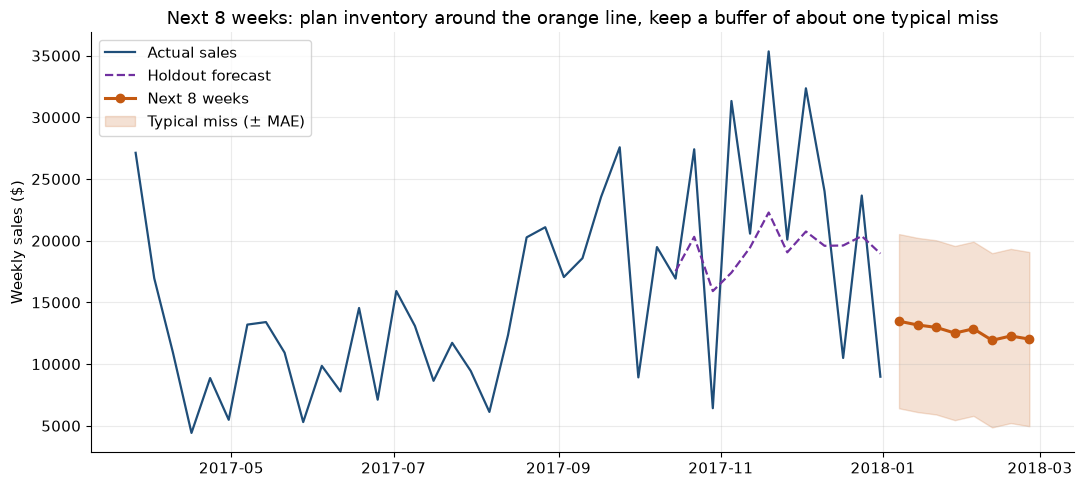

  week_end  forecast     lo      hi
2018-01-07   13477.0 6417.0 20538.0
2018-01-14   13170.0 6110.0 20231.0
2018-01-21   12974.0 5914.0 20035.0
2018-01-28   12513.0 5453.0 19574.0
2018-02-04   12862.0 5801.0 19922.0
2018-02-11   11927.0 4867.0 18988.0
2018-02-18   12278.0 5217.0 19339.0
2018-02-25   12025.0 4964.0 19086.0
Saved /Users/sam/Desktop/Future_ML_01/data/processed/future_8w_forecast.csv


/var/folders/rg/27kh5g0j4b15772f8jyj_z0c0000gn/T/ipykernel_56040/538116181.py:52: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  future.round(2).to_csv(future_path, index=False)
/var/folders/rg/27kh5g0j4b15772f8jyj_z0c0000gn/T/ipykernel_56040/538116181.py:53: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(future.round(0).to_string(index=False))


In [9]:
use_rf = best_name == "Random Forest"
final_model = RandomForestRegressor(
    n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1
) if use_rf else Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=2.0)),
])
final_model.fit(model_ready[FEATURE_COLS], model_ready["sales"])

history = weekly.copy()
future_rows = []
for step in range(HORIZON_WEEKS):
    # The last history row is a known week. We need the *next* week.
    next_end = history["week_end"].iloc[-1] + pd.Timedelta(weeks=1)
    nxt = pd.DataFrame({"week_end": [next_end], "sales": [np.nan], "quantity": [np.nan], "orders": [np.nan]})
    trial = pd.concat([history, nxt], ignore_index=True)
    trial = add_time_features(trial)
    row = trial.iloc[-1]
    x = row[FEATURE_COLS].to_frame().T
    yhat = float(final_model.predict(x)[0])
    yhat = max(yhat, 0.0)
    future_rows.append({"week_end": next_end, "forecast": yhat})
    history = pd.concat([
        history,
        pd.DataFrame({"week_end": [next_end], "sales": [yhat], "quantity": [np.nan], "orders": [np.nan]}),
    ], ignore_index=True)

future = pd.DataFrame(future_rows)
# Operational band = typical weekly miss on holdout (MAE), not a holiday-inflated 95% interval.
typical_miss = float(scoreboard.loc[best_name, "MAE"])
future["lo"] = (future["forecast"] - typical_miss).clip(lower=0)
future["hi"] = future["forecast"] + typical_miss

# Overlay holdout predictions on recent history for a single manager chart.
recent = weekly[weekly["week_end"] >= weekly["week_end"].max() - pd.Timedelta(weeks=40)].copy()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(recent["week_end"], recent["sales"], color="#1f4e79", lw=1.6, label="Actual sales")
ax.plot(test_plot["week_end"], test_plot["predicted"], color="#7030a0", lw=1.6, ls="--", label="Holdout forecast")
ax.plot(future["week_end"], future["forecast"], color="#c45911", lw=2.2, marker="o", label="Next 8 weeks")
ax.fill_between(future["week_end"], future["lo"], future["hi"], color="#c45911", alpha=0.18, label="Typical miss (± MAE)")
ax.set_title("Next 8 weeks: plan inventory around the orange line, keep a buffer of about one typical miss")
ax.set_ylabel("Weekly sales ($)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_future_forecast.png", dpi=140)
plt.show()

future_out = future.copy()
future_out["week_end"] = future_out["week_end"].dt.strftime("%Y-%m-%d")
future_path = PROCESSED_DIR / "future_8w_forecast.csv"
future.round(2).to_csv(future_path, index=False)
print(future.round(0).to_string(index=False))
print("Saved", future_path)


## 8. What this forecast means for the business

The last cell writes a one-page brief a manager can read without opening Python. Numbers are computed from the model above so the story stays in sync with the charts.



In [10]:
last_8 = weekly.tail(8)["sales"].sum()
forecast_sum = float(future["forecast"].sum())
delta_vs_last = forecast_sum - last_8
pct_vs_last = delta_vs_last / last_8 * 100 if last_8 else np.nan
yoy_start = future["week_end"].min() - pd.DateOffset(years=1)
yoy_end = future["week_end"].max() - pd.DateOffset(years=1)
yoy = weekly[(weekly["week_end"] >= yoy_start) & (weekly["week_end"] <= yoy_end)]["sales"].sum()
pct_vs_yoy = (forecast_sum - yoy) / yoy * 100 if yoy else np.nan
holdout_mae = float(scoreboard.loc[best_name, "MAE"])
holdout_mape = float(scoreboard.loc[best_name, "MAPE_%"])
seasonal_mae = float(scoreboard.loc["Seasonal naive (same week last year)", "MAE"])
peak_future = future.loc[future["forecast"].idxmax()]
low_future = future.loc[future["forecast"].idxmin()]
start = future["week_end"].min().strftime("%b %d, %Y")
end = future["week_end"].max().strftime("%b %d, %Y")
last_actual_end = weekly["week_end"].max().strftime("%b %d, %Y")

# Superstore history ends in late December; the 8-week window is early Q1.
q4_avg = weekly[weekly["week_end"].dt.month.isin([11, 12])]["sales"].mean()
q1_avg = weekly[weekly["week_end"].dt.month.isin([1, 2])]["sales"].mean()

brief = f'''# Superstore demand brief

**Forecast window:** {start} – {end}  
**History through:** {last_actual_end}  
**Model used:** {best_name} (holdout MAE ${holdout_mae:,.0f}, MAPE {holdout_mape:.1f}%)

## What the forecast says

We expect about **${forecast_sum:,.0f}** in sales over the next 8 weeks.

That is **{pct_vs_last:+.1f}%** versus the last 8 (holiday) weeks of actuals (${last_8:,.0f}), and **{pct_vs_yoy:+.1f}%** versus the same 8 weeks a year earlier (${yoy:,.0f}). The busiest predicted week is {peak_future["week_end"].strftime("%b %d")} (~${peak_future["forecast"]:,.0f}); the quietest is {low_future["week_end"].strftime("%b %d")} (~${low_future["forecast"]:,.0f}).

This pattern matches Superstore’s calendar: November–December weeks average about ${q4_avg:,.0f}, while January–February weeks average about ${q1_avg:,.0f}. After the holiday spike, demand cools. Plan for a softer first quarter than December, but a stronger start than the 2014–2016 winters because the business has been growing.

## How to use it this week

- **Inventory.** Do not restock holiday-peak quantities into January. Lean into Office Supplies (largest order count) for steady replenishment; keep furniture and technology closer to the forecast band so cash is not sitting in slow movers.
- **Cash.** The next 8 weeks total ~${forecast_sum:,.0f}. If last year’s Q1 conversion of sales-to-cash holds, this is the receipts envelope for rent, suppliers, and payroll. Stress-test a buffer of about ${holdout_mae:,.0f} per week (the model’s typical miss) before committing to big POs.
- **Staffing.** Peak weeks in this window still need floor and shipping coverage, but fewer extra seasonal hours than November–December. Schedule down toward the quieter weeks rather than keeping holiday headcount.

## How good is the number?

On the last 12 weeks (mostly holiday peak), the chosen model’s average miss was **${holdout_mae:,.0f} per week** ({holdout_mape:.1f}% MAPE). That beat last-year-same-week (${seasonal_mae:,.0f} MAE). Percentage error looks high because December weeks swing hard; use the dollar MAE as the planning buffer. If a promotion, store opening, or stockout is coming that did not exist in 2014–2017, override the model.

## Caveats

- History is 2014–2017 U.S. Superstore orders. There is no COVID shock in this file, and there are no 2018+ prices.
- One national weekly total hides regional mix (West and East dominate). A regional manager should split the same pipeline by `Region` before buying local inventory.
- Empty weeks were treated as true zeros, not missing data.
- The shaded range is ± the holdout MAE, not a statistical guarantee.

## Bottom line

Treat **${forecast_sum:,.0f} over 8 weeks** as the planning midpoint. Buy and staff below holiday-peak levels, keep a buffer up to the top of the band, and revisit the forecast after the first two actual weeks of the new year.
'''

brief_path = REPORTS_DIR / "BUSINESS_BRIEF.md"
brief_path.write_text(brief)
print(brief)
print("\nWrote", brief_path)


# Superstore demand brief

**Forecast window:** Jan 07, 2018 – Feb 25, 2018  
**History through:** Dec 31, 2017  
**Model used:** Random Forest (holdout MAE $7,061, MAPE 44.6%)

## What the forecast says

We expect about **$101,227** in sales over the next 8 weeks.

That is **-42.3%** versus the last 8 (holiday) weeks of actuals ($175,501), and **+78.4%** versus the same 8 weeks a year earlier ($56,730). The busiest predicted week is Jan 07 (~$13,477); the quietest is Feb 11 (~$11,927).

This pattern matches Superstore’s calendar: November–December weeks average about $19,516, while January–February weeks average about $5,073. After the holiday spike, demand cools. Plan for a softer first quarter than December, but a stronger start than the 2014–2016 winters because the business has been growing.

## How to use it this week

- **Inventory.** Do not restock holiday-peak quantities into January. Lean into Office Supplies (largest order count) for steady replenishment; keep furniture and 